In [1]:
import pandas as pd
import re
import emoji


# Loading

In [2]:
df = pd.read_csv("goud_articles_split_part_1.csv")


In [4]:
df.shape

(8242, 6)

In [5]:
print(df.columns.values)

['title' 'url' 'category' 'content' 'published_time' 'modified_time']


---
# Cleaning 

In [6]:
# check for duplicates in the subset of title content column
print("nbr de duplicates pour la col 'content' : ", df.duplicated(subset=['content']).sum())

nbr de duplicates pour la col 'content' :  7


In [7]:
# drop duplicates in the subset of  content column
df = df.drop_duplicates(subset=['content'])

In [8]:
# check for null values by column
df.isnull().sum()


title                0
url                  0
category             0
content              1
published_time       0
modified_time     1941
dtype: int64

In [9]:
df.isna()
df[df.isna()["content"] == True]

,title,url,category,content,published_time,modified_time
2176,ستوك سيتي تفارقو مع ريان مايي,https://www.goud.ma/%d8%b3%d8%aa%d9%88%d9%83-%...,كود سبور,NaN,2025-08-20 12:00:19+00:00,2025-08-20T11:10:49+00:00


> - we extracted manually the context using url for id = 2176

In [10]:
# extracted content from url
content_2176='''
گود سبور//
تفارق الدولي المغربي ريان مايي من ستوك سيتي النگليزي، بعدما دوز معهم 2 مواسم.
وأعلن ستوكي سيتي النگليري صباح اليوم الاربعاء، انه تفارق مع ريان مايي، بعدما توصل هو والمهاجم المغربي لاتفاق على الانفصال بالتراضي، مع العلم ان العقد ديال الطرفين ما كان غايسالي حتى صيف 2026.
ريان مايي مول 27 عام، لعب مع ستوك سيتي 27 ماتش ماركا فيهم 3 اهداف.
'''
df.loc[2176, 'content'] = content_2176
df.iloc[[2176]]


,title,url,category,content,published_time,modified_time
2176,ستوك سيتي تفارقو مع ريان مايي,https://www.goud.ma/%d8%b3%d8%aa%d9%88%d9%83-%...,كود سبور,\nگود سبور//\nتفارق الدولي المغربي ريان مايي م...,2025-08-20 12:00:19+00:00,2025-08-20T11:10:49+00:00


In [11]:
# drop null values 
df = df.dropna(subset=['content']) 
df.isna().sum()

title                0
url                  0
category             0
content              0
published_time       0
modified_time     1941
dtype: int64

In [12]:
df['content'].apply(lambda x: len(x.split())).idxmax()

np.int64(3657)

In [13]:
df.shape

(8235, 6)

In [14]:


def extract_and_clean_context(raw_content):
    # Handle non-string values
    if not isinstance(raw_content, str):
        return ""
    
    # 1. Split the text into lines
    lines = raw_content.split('\n')
    
    # 2. Remove "Spam" (Goud.ma specific author signatures) from the beginning of the article ( the first line)
    # Pattern  like: "الوالي الزاز -كود- العيون//" or "عمر – كود//"

    
    clean_lines = [
        line.strip() for line in lines[1:] 
        if line.strip() 
        and not line.strip() == "[email protected]"
        and not re.match(r'\[email\s*protected\]', line.strip(), re.IGNORECASE)
    ]
    
    # If the article is empty after filtering, return nothing
    if not clean_lines:
        return ""
        
    # 3. Isolate the true first paragraph (add next paragraphs if the first one is too short and there are more paragraphs)
    if len(clean_lines[0].split()) < 5 and len(clean_lines) > 1:    # 5 word treshhold
        first_paragraph = clean_lines[0] + " " + clean_lines[1]
    else:
        first_paragraph = clean_lines[0]

    
    # 4. Remove URLs
    first_paragraph = re.sub(r'https?://\S+|www\.\S+', '', first_paragraph)
    
    # 5. Remove Emojis
    first_paragraph = emoji.replace_emoji(first_paragraph, replace='')
    
    # 6. Final cleanup
    first_paragraph = re.sub(r'\s+', ' ', first_paragraph).strip()
    
    return first_paragraph

test

In [ ]:

# --- Testing on the data ---
raw_text = """عمر المزين – كود////
حصلت “كود” على تفاصيل اتهام مصطفى لخصم رئيس جماعة إيموزار كندر بشبهة “اختلاس وتبديد أموال عمومية”، وهي القضية التي شرعت الفرقة الجهوية للشرطة القضائية بفاس في إجراء الأبحاث والتحريات بشأنها.
وحسب ما أكدته مصادر “كود”، فإن مستشار بالجماعة المذكورة..."""

cleaned_context = extract_and_clean_context(raw_text)
cleaned_context

'حصلت “كود” على تفاصيل اتهام مصطفى لخصم رئيس جماعة إيموزار كندر بشبهة “اختلاس وتبديد أموال عمومية”، وهي القضية التي شرعت الفرقة الجهوية للشرطة القضائية بفاس في إجراء الأبحاث والتحريات بشأنها.'

In [16]:

# --- Testing with your data ---
raw_text = """عمر المزين – كود
ثبثب


رسرسسرسرقسر"""

cleaned_context = extract_and_clean_context(raw_text)
cleaned_context

'ثبثب رسرسسرسرقسر'

In [17]:


# 2. Apply the function to the 'content' column
# This reads every row's 'content', runs our cleaning function, 
# and saves the output into a brand new column called 'context'
df['context'] = df['content'].apply(extract_and_clean_context)

# 3. Handle empty contexts
# Sometimes an article might just be a video or an image with no text. 
# Let's filter out any rows where our cleaning function returned an empty string.
df = df[df['context'] != ""]

# 4. Check your work!
# Let's look at the original title alongside our newly extracted context
df[['title', 'context']].head()

,title,context
0,تفاصيل اتهام لخصم باختلاس وتبديد فلوس عمومية.....,حصلت “كود” على تفاصيل اتهام مصطفى لخصم رئيس جم...
1,مسؤول مريكاني: واشنطن بغات تقرب بين المغرب وال...,فتصريح لقناة العربية، قال مستشار شؤون الشرق ال...
2,المجلس الاقتصادي والاجتماعي والبيئي: حجم نفايا...,أكد المجلس الاقتصادي والاجتماعي والبيئي أن الأ...
3,قضية إلياس المالكي.. حريرتو مشات للشهر الجاي ل...,علمت “كود” أن غرفة الجنح التلبسية بالمحكمة الا...
4,الوزيرة فتاح علوي كشفات على الحالات الاستثنائي...,أفادت نادية فتاح علوي، وزيرة الاقتصاد والمالية...


# Initial EDA

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8219 entries, 0 to 8241
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   title           8219 non-null   object
 1   url             8219 non-null   object
 2   category        8219 non-null   object
 3   content         8219 non-null   object
 4   published_time  8219 non-null   object
 5   modified_time   6281 non-null   object
 6   context         8219 non-null   object
dtypes: object(7)
memory usage: 513.7+ KB


In [19]:
print("nombre total de documents : ", len(df))
print("nombre minimum de mots dans le corpus : ", df['content'].apply(lambda x: len(x.split())).sum())
print("nombre minimum de mots dans l'article : ", df['content'].apply(lambda x: len(x.split())).min())
print("nombre maximum de mots dans l'article : ", df['content'].apply(lambda x: len(x.split())).max())
print("nombre moyen de mots dans l'article : ", df['content'].apply(lambda x: len(x.split())).mean())
print("nombre median de mots dans l'article : ", df['content'].apply(lambda x: len(x.split())).median())

nombre total de documents :  8219
nombre minimum de mots dans le corpus :  1732636
nombre minimum de mots dans l'article :  1
nombre maximum de mots dans l'article :  1843
nombre moyen de mots dans l'article :  210.8086141866407
nombre median de mots dans l'article :  166.0


In [20]:
# affichage de toutes les lignes du dataframe qui contient au maximum 9 mots dans la colonne 'content'
df[df['content'].apply(lambda x: len(x.split()) <= 9)]

,title,url,category,content,published_time,modified_time,context
1045,غير بالتصاور كيفاش كانت لامبيانس فتداريب الأسو...,https://www.goud.ma/%d8%ba%d9%8a%d8%b1-%d8%a8%...,كود سبور,\n\n\n\n\n\n\n\n\n\n\\n,2025-03-19 10:18:27+00:00,2025-03-19T10:50:40+00:00,\


In [21]:
# suppression de la ligne 1045 that is empty contexts already  from the original source  (it was only image posted)
df = df.drop(index=1045)
df = df[df['context'].notnull() & df['context'].str.strip() != '']

In [22]:
df.head()

,title,url,category,content,published_time,modified_time,context
0,تفاصيل اتهام لخصم باختلاس وتبديد فلوس عمومية.....,https://www.goud.ma/%d8%aa%d9%81%d8%a7%d8%b5%d...,آش واقع,عمر المزين – كود//\nحصلت “كود” على تفاصيل اتها...,2024-09-24 11:30:36+00:00,2024-09-24T11:26:15+00:00,حصلت “كود” على تفاصيل اتهام مصطفى لخصم رئيس جم...
1,مسؤول مريكاني: واشنطن بغات تقرب بين المغرب وال...,https://www.goud.ma/%d9%85%d8%b3%d8%a4%d9%88%d...,آش واقع,محمود الركيبي -كود- العيون //\nفتصريح لقناة ال...,2025-04-18 16:30:39+00:00,2025-04-18T16:25:40+00:00,فتصريح لقناة العربية، قال مستشار شؤون الشرق ال...
2,المجلس الاقتصادي والاجتماعي والبيئي: حجم نفايا...,https://www.goud.ma/%d8%a7%d9%84%d9%85%d8%ac%d...,آش واقع,عمر المزين – كود///\nأكد المجلس الاقتصادي والا...,2025-07-01 15:51:14+00:00,NaN,أكد المجلس الاقتصادي والاجتماعي والبيئي أن الأ...
3,قضية إلياس المالكي.. حريرتو مشات للشهر الجاي ل...,https://www.goud.ma/%d9%82%d8%b6%d9%8a%d8%a9-%...,تبركيك,عمر المزين – كود//\nعلمت “كود” أن غرفة الجنح ا...,2025-11-28 20:00:43+00:00,2025-11-28T19:45:40+00:00,علمت “كود” أن غرفة الجنح التلبسية بالمحكمة الا...
4,الوزيرة فتاح علوي كشفات على الحالات الاستثنائي...,https://www.goud.ma/%d8%a7%d9%84%d9%88%d8%b2%d...,آش واقع,عمر المزين – كود///\nأفادت نادية فتاح علوي، وز...,2025-09-04 13:44:06+00:00,NaN,أفادت نادية فتاح علوي، وزيرة الاقتصاد والمالية...


> - discovering optimal treshold to use 

In [23]:
# affichage de toutes les lignes du dataframe qui contient au maximum 9 mots dans la colonne 'content'
df[df['context'].apply(lambda x: len(x.split()) <= 1)]["context"].count()


np.int64(0)

In [24]:
df[df['context'].apply(lambda x: len(x.split()) <= 2)]["context"].count()

np.int64(0)

In [25]:
df[df['context'].apply(lambda x: len(x.split()) <= 3)]["context"].count()

np.int64(0)

In [26]:
print("Number of contexts with 4 or fewer words:",df[df['context'].apply(lambda x: len(x.split()) <= 4)]["context"].count())
df[df['context'].apply(lambda x: len(x.split()) <= 4)][["context"]]

Number of contexts with 4 or fewer words: 1


,context
2934,أخذوا خروفه. أخذوا دوارته.


In [27]:
print("Number of contexts with 5 or fewer words:",df[df['context'].apply(lambda x: len(x.split()) <= 5)]["context"].count())
df[df['context'].apply(lambda x: len(x.split()) <= 5)][["context"]]

Number of contexts with 5 or fewer words: 16


,context
599,لا يهمني كثيرا عزيز أخنوش.
2455,انسوا. انسوا نبيلة منيب السابقة.
2926,كل الذين انتقدوا دلوعتنا المغربية.
2934,أخذوا خروفه. أخذوا دوارته.
2953,نحن لسنا علماء يا الله.
3389,ليس للنظام الجزائري أي شيء.
4032,ما اسمها. يقول وزير العدل.
4254,الدولة بدورها تكره هذه الرتابة.
4617,لستُ ضد دخولكن إلى الملعب.
5460,لِنضعْ المهدي بنسعيد وسط الصورة.


# saving + id if join needed later

In [28]:
# Add a simple generated ID column starting from 1 
df['id'] = range(1, len(df) + 1)

# Save with the new 'id' column included, keeping Arabic characters preserved
df[['id', 'title', 'context', 'content', 'url']].to_csv('cleaned_articles_split_part_1.csv', index=False, encoding='utf-8')

# final EDA & visualization

In [29]:
df = pd.read_csv('cleaned_articles_split_part_1.csv', encoding='utf-8')
df.head()

,id,title,context,content,url
0,1,تفاصيل اتهام لخصم باختلاس وتبديد فلوس عمومية.....,حصلت “كود” على تفاصيل اتهام مصطفى لخصم رئيس جم...,عمر المزين – كود//\nحصلت “كود” على تفاصيل اتها...,https://www.goud.ma/%d8%aa%d9%81%d8%a7%d8%b5%d...
1,2,مسؤول مريكاني: واشنطن بغات تقرب بين المغرب وال...,فتصريح لقناة العربية، قال مستشار شؤون الشرق ال...,محمود الركيبي -كود- العيون //\nفتصريح لقناة ال...,https://www.goud.ma/%d9%85%d8%b3%d8%a4%d9%88%d...
2,3,المجلس الاقتصادي والاجتماعي والبيئي: حجم نفايا...,أكد المجلس الاقتصادي والاجتماعي والبيئي أن الأ...,عمر المزين – كود///\nأكد المجلس الاقتصادي والا...,https://www.goud.ma/%d8%a7%d9%84%d9%85%d8%ac%d...
3,4,قضية إلياس المالكي.. حريرتو مشات للشهر الجاي ل...,علمت “كود” أن غرفة الجنح التلبسية بالمحكمة الا...,عمر المزين – كود//\nعلمت “كود” أن غرفة الجنح ا...,https://www.goud.ma/%d9%82%d8%b6%d9%8a%d8%a9-%...
4,5,الوزيرة فتاح علوي كشفات على الحالات الاستثنائي...,أفادت نادية فتاح علوي، وزيرة الاقتصاد والمالية...,عمر المزين – كود///\nأفادت نادية فتاح علوي، وز...,https://www.goud.ma/%d8%a7%d9%84%d9%88%d8%b2%d...


In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the word count for each context and save it in a new column
df['word_count'] = df['context'].apply(lambda x: len(str(x).split()))

# Display a quick statistical summary (mean, min, max, etc.)
print(df['word_count'].describe())

count    8218.000000
mean       34.229618
std        23.095301
min         4.000000
25%        24.000000
50%        31.000000
75%        39.000000
max       593.000000
Name: word_count, dtype: float64


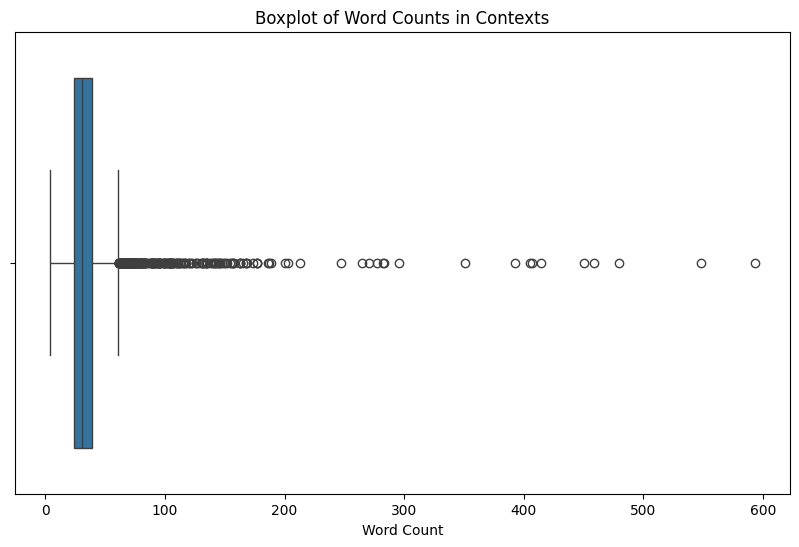

In [31]:
# boite à moustaches
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['word_count'])
plt.title('Boxplot of Word Counts in Contexts')
plt.xlabel('Word Count')
plt.show()

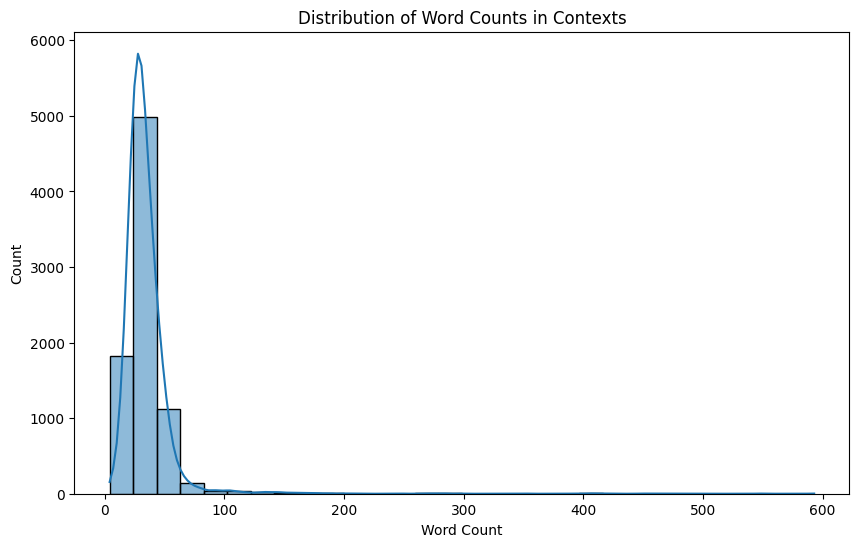

In [32]:
# histogramme
plt.figure(figsize=(10, 6))
sns.histplot(df['word_count'], bins=30, kde=True)
plt.title('Distribution of Word Counts in Contexts')
plt.xlabel('Word Count')
plt.show()

In [33]:
# what the word count 99th percentile
word_count_99th_percentile = df['word_count'].quantile(0.99)
wc_99th_int = int(word_count_99th_percentile)
print("99th percentile of word counts in contexts:", wc_99th_int)

99th percentile of word counts in contexts: 109


In [34]:
#  winzorize the the context lengths for context with more than 100 words to be capped at 100 words only (capping at 100 word is the (0.9877)99th percentile)
df['context_capped'] = df['context'].apply(lambda x: ' '.join(str(x).split()[:wc_99th_int]) if len(str(x).split()) > wc_99th_int else x)

In [35]:

# Calculate the word count for each context and save it in a new column
df['word_count_capped'] = df['context_capped'].apply(lambda x: len(str(x).split()))

# Display a quick statistical summary (mean, min, max, etc.)
print(df['word_count_capped'].describe())

count    8218.000000
mean       33.387686
std        14.852415
min         4.000000
25%        24.000000
50%        31.000000
75%        39.000000
max       109.000000
Name: word_count_capped, dtype: float64


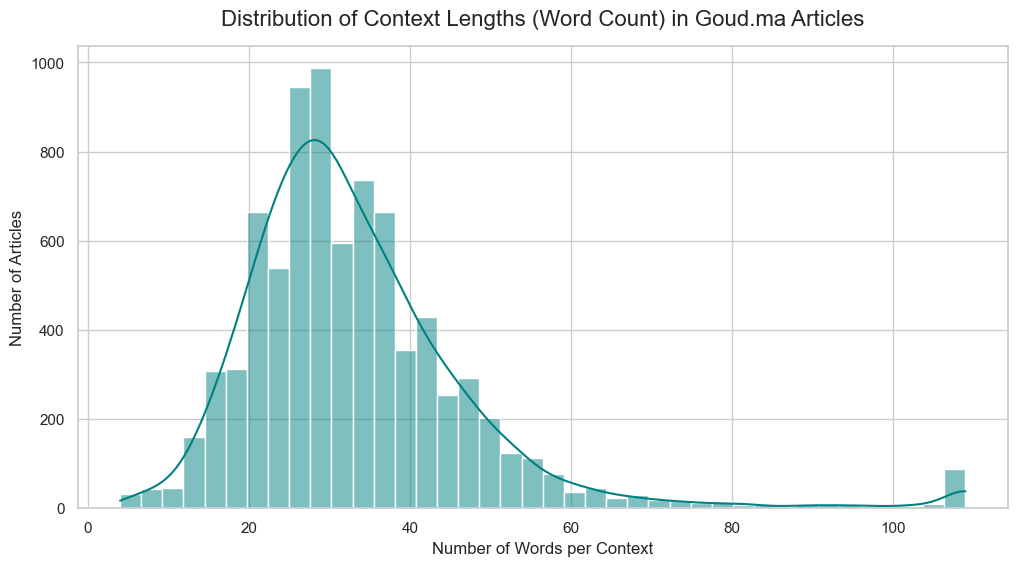

In [36]:
# Set the visual style for the plot
sns.set_theme(style="whitegrid")

# Create the figure with a specific size
plt.figure(figsize=(12, 6))

# Plot the histogram with a KDE curve
sns.histplot(data=df, x='word_count_capped', bins=40, kde=True, color='teal')

# Add titles and labels to make the chart report-ready
plt.title('Distribution of Context Lengths (Word Count) in Goud.ma Articles', fontsize=16, pad=15)
plt.xlabel('Number of Words per Context', fontsize=12)
plt.ylabel('Number of Articles', fontsize=12)

# Display the plot
plt.show()

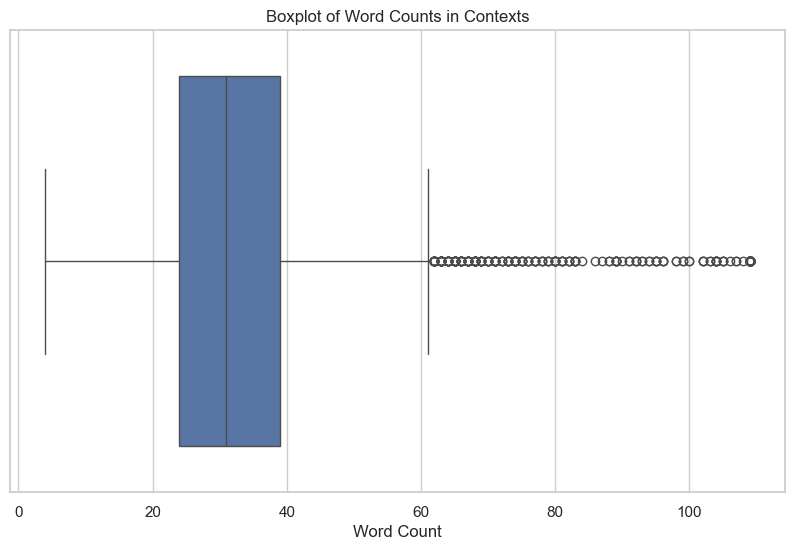

In [37]:
# boite à moustaches
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['word_count_capped'])
plt.title('Boxplot of Word Counts in Contexts')
plt.xlabel('Word Count')
plt.show()

In [42]:
# check for duplicates in the subset of title content column
print("nbr de duplicates pour la col 'context_capped' : ", df.duplicated(subset=['context_capped']).sum())

nbr de duplicates pour la col 'context_capped' :  6


In [43]:
# afficher les dupplicates
df[df[['context_capped']].duplicated(keep=False)]

,id,title,context,content,url,word_count,context_capped,word_count_capped,repetitions,latin_chars
2550,2551,النيابة العامة ففاس كتستنطق شبكة النصب على الل...,تواصل النيابة العامة لدى المحكمة الابتدائية بم...,عمر المزين – كود///\nتواصل النيابة العامة لدى ...,https://www.goud.ma/%d8%a7%d9%84%d9%86%d9%8a%d...,39,تواصل النيابة العامة لدى المحكمة الابتدائية بم...,39,0,0
2859,2860,تقرير مرفوع من گوتيريش حول الصحرا للجمعية العا...,قدم الأمين العام للأمم المتحدة، أنطونيو گوتيري...,الوالي الزاز -كود- العيون/// [email protected]...,https://www.goud.ma/%d8%aa%d9%82%d8%b1%d9%8a%d...,41,قدم الأمين العام للأمم المتحدة، أنطونيو گوتيري...,41,0,0
3585,3586,جديد فضايح جسور رئيس قسم الصفقات والميزانية بو...,قررت غرفة الجنايات الابتدائية المكلفة بالبث في...,عمـر المزين – كود//\nقررت غرفة الجنايات الابتد...,https://www.goud.ma/%d8%ac%d8%af%d9%8a%d8%af-%...,41,قررت غرفة الجنايات الابتدائية المكلفة بالبث في...,41,0,0
4317,4318,فضايح التلاعب بالصفقات العمومية بولاية جهة فاس...,قررت غرفة الجنايات الابتدائية المكلفة بالبث في...,عمـر المزين – كود//\nقررت غرفة الجنايات الابتد...,https://www.goud.ma/%d9%81%d8%b6%d8%a7%d9%8a%d...,44,قررت غرفة الجنايات الابتدائية المكلفة بالبث في...,44,0,0
4501,4502,تقرير مرفوع من گوتيريش حول الصحرا للجمعية العا...,قدم الأمين العام للأمم المتحدة، أنطونيو گوتيري...,الوالي الزاز -كود- العيون//// [email protected...,https://www.goud.ma/%d8%aa%d9%82%d8%b1%d9%8a%d...,41,قدم الأمين العام للأمم المتحدة، أنطونيو گوتيري...,41,0,0
6090,6091,عاجل. النيابة العامة ففاس بدات مع نصابة الهجرة...,تواصل النيابة العامة لدى المحكمة الابتدائية بم...,‎عمر المزين – كود///\nتواصل النيابة العامة لدى...,https://www.goud.ma/%d8%b9%d8%a7%d8%ac%d9%84-%...,39,تواصل النيابة العامة لدى المحكمة الابتدائية بم...,39,0,0
6104,6105,لإتمام المرافعات.. فضايح جسور رئيس قسم الميزان...,قررت غرفة الجنايات الابتدائية المكلفة بالبث في...,عمـر المزين – كود//\nقررت غرفة الجنايات الابتد...,https://www.goud.ma/%d9%84%d8%a5%d8%aa%d9%85%d...,44,قررت غرفة الجنايات الابتدائية المكلفة بالبث في...,44,0,0
6420,6421,جديد فضايح رئيس قسم الصفقات والميزانية بولاية ...,قررت غرفة الجنايات الابتدائية المكلفة بالبث في...,عمـر المزين – كود//\nقررت غرفة الجنايات الابتد...,https://www.goud.ma/%d8%ac%d8%af%d9%8a%d8%af-%...,41,قررت غرفة الجنايات الابتدائية المكلفة بالبث في...,41,0,0
6574,6575,تعيينات جديدة فمناصب عليا دازت فالمجلس الحكومي...,صادق مجلس الحكومة، اليوم الخميس، على مقترحات ت...,عمر المزين – كود//\nصادق مجلس الحكومة، اليوم ا...,https://www.goud.ma/%d8%aa%d8%b9%d9%8a%d9%8a%d...,16,صادق مجلس الحكومة، اليوم الخميس، على مقترحات ت...,16,0,0
6920,6921,المجلس الحكومي.. ها التعيينات فالمناصب العليا ...,صادق مجلس الحكومة، اليوم الخميس، على مقترحات ت...,عمر المزين – كود///\nصادق مجلس الحكومة، اليوم ...,https://www.goud.ma/%d8%a7%d9%84%d9%85%d8%ac%d...,16,صادق مجلس الحكومة، اليوم الخميس، على مقترحات ت...,16,0,0
